<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_21_Predict_Token_Position_with_Linear_and_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from datasets import load_dataset

from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.metrics import confusion_matrix
import statsmodels.api as sm
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer


# Part_1:Create a Dataset

## Task_1:
- Import GPT-2 and its tokenizer.
Import the hellaswag validation set from the Hugging Face
load_dataset library (same library you used to import Wikitext).
Create a “batch” of tokens to input to the model. A batch is simply
a collection of token sequences, organized into a PyTorch tensor,
that the model processes in parallel. In a for-loop over the first 500
text samples of HellaSwag, tokenize the text from the ctx_a key, and
store the first six tokens. The result will be a 500×6 tensor of tokens.
Push the tokens through the model and check the size of the
output logits

In [2]:
# load pretrained GPT-2 model and tokenizer
tokenizer = AutoTokenizer.from_pretrained('gpt2')
model = AutoModelForCausalLM.from_pretrained('gpt2')
model.eval()

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [3]:
# import the HellaSwag validation set
dataset = load_dataset('allenai/hellaswag',split='validation')
dataset

README.md:   0%|          | 0.00/823 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 24.3MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.09MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.29MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/39905 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10042 [00:00<?, ? examples/s]

Dataset({
    features: ['ind', 'activity_label', 'ctx_a', 'ctx_b', 'ctx', 'endings', 'source_id', 'split', 'split_type', 'label'],
    num_rows: 10042
})

In [4]:
torch.zeros((2,3))

tensor([[0., 0., 0.],
        [0., 0., 0.]])

In [6]:
# batch parameters
seqlen = 6
nSamples = 500

# initialize the batch
batch = torch.zeros((nSamples,seqlen),dtype=torch.long)

# get the tokens for each sequence
for i in range(nSamples):
  firsttokens = tokenizer.encode(dataset[i]['ctx_a'])[:seqlen]
  batch[i,:] = torch.tensor(firsttokens)

print(f'Shape of batch: {batch.shape}')
batch


Shape of batch: torch.Size([500, 6])


tensor([[   32,   582,   318,  5586,   319,   257],
        [   32, 10846, 11114,   284,   257,  2318],
        [ 7571,  1466,   287,   257,  1200,   389],
        ...,
        [   32, 42966, 17445,   656,   257, 10308],
        [   32,   582,   318,  1762,  2354,   287],
        [   32,   582,   318,  1762,  2354,   287]])

In [11]:
batch[13,:]

tensor([ 1544,   788, 19748,   257,  1310,  2042])

In [12]:
tokenizer.decode(batch[13,:])

'He then notices a little black'

In [14]:
tokenizer.decode(batch[2,:])

'Two women in a child are'

In [15]:
with torch.no_grad():
  outputs=model(batch)

outputs.logits.shape

torch.Size([500, 6, 50257])

## Task_2:
- Create a 500 × 5 NumPy array of losses. Remember that the logits
are predictions about the next token, which means that the first
token in a sequence cannot be predicted. Therefore, the five columns
in the data matrix correspond to single-token losses for the first
through fifth tokens, making predictions about the second through
the sixth tokens.To populate that matrix, create a double for-loop over sequences and tokens, find each target token index, and extract the loss as the
negative log-softmax at the target token position.
You will also need an equal-sized matrix of ordinal positions
for the regression analysis. That matrix is simply the integers 0, 1,
2, 3, 4 repeated 500 times. Flatten (vectorize) both data matrices to
create 2500 × 1 arrays.
Finally, visualize the position-specific losses as in Figure 4.21.

In [17]:
# log-softmax to get losses
logits_logsm = F.log_softmax(outputs.logits,dim=-1)

# initialize matrix of losses
losses = np.zeros((nSamples,seqlen-1))

# loop over sequences and tokens
for seqi in range(nSamples):
  for tokeni in range(seqlen-1):

    # single-token loss is -loglikelihood of target token
    target_idx = batch[seqi,tokeni+1]
    losses[seqi,tokeni] = -logits_logsm[seqi,tokeni,target_idx].item()

In [18]:
ord_position = np.tile(np.arange(seqlen-1),(nSamples,1))
ord_position

array([[0, 1, 2, 3, 4],
       [0, 1, 2, 3, 4],
       [0, 1, 2, 3, 4],
       ...,
       [0, 1, 2, 3, 4],
       [0, 1, 2, 3, 4],
       [0, 1, 2, 3, 4]])

In [19]:
ord_position.shape

(500, 5)

In [21]:
losses_flat = losses.flatten().reshape(-1,1)
ord_position_flat = ord_position.flatten().reshape(-1,1)

print(f'           Shape of losses: {losses.shape}')
print(f'      Shape of losses_flat: {losses_flat.shape}\n')
print(f'     Shape of ord_position: {ord_position.shape}')
print(f'Shape of ord_position_flat: {ord_position_flat.shape}')

           Shape of losses: (500, 5)
      Shape of losses_flat: (2500, 1)

     Shape of ord_position: (500, 5)
Shape of ord_position_flat: (2500, 1)


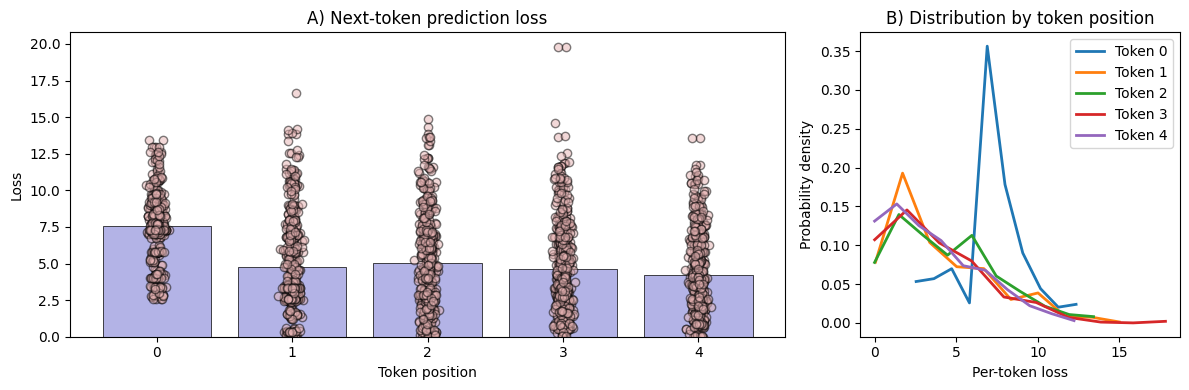

In [22]:
# setup the figure and axes
fig = plt.figure(figsize=(12,4))
gs = GridSpec(1,3,figure=fig)
ax1 = fig.add_subplot(gs[:-1])
ax2 = fig.add_subplot(gs[-1])

# bar plot and scatter
ax1.bar(range(seqlen-1),losses.mean(axis=0),color=[.7,.7,.9],edgecolor='k',linewidth=.5)
ax1.plot(ord_position_flat+np.random.normal(0,.03,ord_position_flat.shape),
         losses_flat,'ko',markerfacecolor=[.9,.7,.7,.5])

ax1.set(xlabel='Token position',ylabel='Loss',title='A) Next-token prediction loss')


# distributions
for i in range(seqlen-1):
  y,x = np.histogram(losses[:,i],bins=10,density=True)
  ax2.plot(x[:-1],y,linewidth=2,label=f'Token {i}')

ax2.set(xlabel='Per-token loss',ylabel='Probability density',title='B) Distribution by token position')
ax2.legend()

plt.tight_layout()
plt.show()


# Part_2:Linear Regression in StatsModel and ScikitLearn

## Task_1:
- Use the OLS method in the statsmodels library (often abbreviated
to sm) to regress the flattened losses onto the flattened ordinal
positions vector. The design matrix of the regression needs two
columns: an intercept and the independent variable. The intercept
is a column of 1’s and can be added using sm.add_constant, and
the independent variable is the losses.
Print the regression summary. See how many details in the
summary table you are familiar with — and keep in mind that
there’s much more information in the table than what you need for
this project.

In [25]:
# create and fit the model
X = sm.add_constant(losses_flat) # design matrix with intercept term
smreg = sm.OLS(ord_position_flat,X).fit()
print( smreg.summary() )

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.099
Model:                            OLS   Adj. R-squared:                  0.099
Method:                 Least Squares   F-statistic:                     274.2
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           1.59e-58
Time:                        08:15:54   Log-Likelihood:                -4283.6
No. Observations:                2500   AIC:                             8571.
Df Residuals:                    2498   BIC:                             8583.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.7474      0.053     52.309      0.0